In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tiny 5x5 "image" with a bright horizontal bar
img = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
], dtype=float)

# Simple horizontal edge detector (Sobel-like)
kernel = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1],
], dtype=float)

img_df = pd.DataFrame(img)
kernel_df = pd.DataFrame(kernel)

print("Our image:")
img_df

Our image:


,0,1,2,3,4
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,1.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0


In [2]:
def conv2d_valid(x, k):
    H, W = x.shape
    kH, kW = k.shape
    out = np.zeros((H - kH + 1, W - kW + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            # row i to i+kH , column j to j+kW
            patch = x[i:i+kH, j:j+kW]
            out[i, j] = np.sum(patch * k)
    return out

edge = conv2d_valid(img, kernel)
edge_df = pd.DataFrame(edge)
print("Our edge-detecting kernel:")
edge_df

Our edge-detecting kernel:


,0,1,2
0,3.0,4.0,3.0
1,0.0,0.0,0.0
2,-3.0,-4.0,-3.0


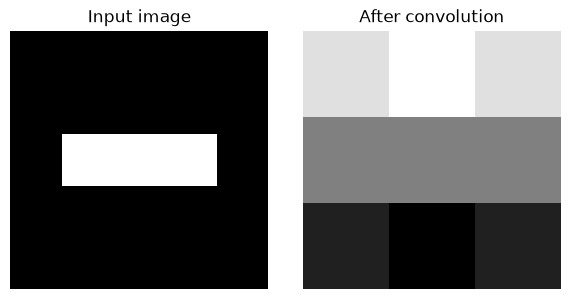

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Input image")
axes[0].axis("off")

axes[1].imshow(edge, cmap="gray")
axes[1].set_title("After convolution")
axes[1].axis("off")
plt.tight_layout()

In [4]:
def max_pool2d(x, pool_size=2, stride=2):
    H, W = x.shape
    out_H = (H - pool_size) // stride + 1
    out_W = (W - pool_size) // stride + 1
    out = np.zeros((out_H, out_W))
    for i in range(out_H):
        for j in range(out_W):
            patch = x[i*stride:i*stride+pool_size,
                      j*stride:j*stride+pool_size]
            out[i, j] = patch.max()
    return out

pooled = max_pool2d(edge, pool_size=2, stride=1)
pd.DataFrame(pooled)

,0,1
0,4.0,4.0
1,0.0,0.0


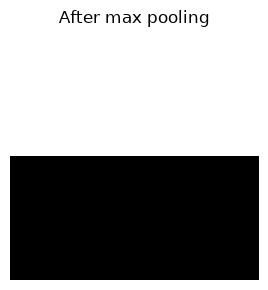

In [5]:
plt.figure(figsize=(3, 3))
plt.imshow(pooled, cmap="gray")
plt.title("After max pooling")
plt.axis("off")
plt.tight_layout()

# MLP vs CNN on (some) CIFAR-10
## Goal
- Compare a baseline MLP vs a small CNN on image data
## Setup & data

In [6]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5)),
])

train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
test_full = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)

# Use a small subset to keep training fast (e.g., 5000 train, 1000 test)
np.random.seed(0)
train_indices = np.random.choice(len(train_full), size=5000, replace=False)
test_indices = np.random.choice(len(test_full), size=1000, replace=False)

train_subset = Subset(train_full, train_indices)
test_subset = Subset(test_full, test_indices)

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=64, shuffle=False)

mps


In [7]:
# Models: MLP baseline
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)

mlp = MLPClassifier().to(device)

In [8]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),   # 32x16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),   # 64x8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

cnn = SmallCNN().to(device)

In [9]:
# Training helper
def train_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total

In [10]:
def run_experiment(model, train_loader, test_loader, epochs=5, lr=1e-3):
    # torch.nn.CrossEntropyLoss is a standard PyTorch loss function
    # used for multi-class classification tasks.
    # It combines nn.LogSoftmax() and nn.NLLLoss() into a single class
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [],
               "test_loss": [], "test_acc": []}

    for epoch in range(epochs):
        tl, ta = train_epoch(model, train_loader, optimizer, loss_fn)
        vl, va = evaluate(model, test_loader, loss_fn)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["test_loss"].append(vl)
        history["test_acc"].append(va)
        print(f"Epoch {epoch+1}: "
              f"train_acc={ta:.3f}, test_acc={va:.3f}")
    return history

mlp_hist = run_experiment(mlp, train_loader, test_loader, epochs=5, lr=1e-3)
cnn_hist = run_experiment(cnn, train_loader, test_loader, epochs=5, lr=1e-3)

Epoch 1: train_acc=0.324, test_acc=0.339
Epoch 2: train_acc=0.441, test_acc=0.344
Epoch 3: train_acc=0.502, test_acc=0.385
Epoch 4: train_acc=0.557, test_acc=0.376
Epoch 5: train_acc=0.605, test_acc=0.377
Epoch 1: train_acc=0.329, test_acc=0.392
Epoch 2: train_acc=0.477, test_acc=0.437
Epoch 3: train_acc=0.529, test_acc=0.500
Epoch 4: train_acc=0.583, test_acc=0.483
Epoch 5: train_acc=0.616, test_acc=0.503


In [11]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

summary = pd.DataFrame({
    "model": ["MLP", "CNN"],
    "params": [count_params(mlp), count_params(cnn)],
    "train_acc": [mlp_hist["train_acc"][-1],
                  cnn_hist["train_acc"][-1]],
    "test_acc": [mlp_hist["test_acc"][-1],
                 cnn_hist["test_acc"][-1]],
})

summary

,model,params,train_acc,test_acc
0,MLP,1578506,0.6046,0.377
1,CNN,60362,0.6164,0.503


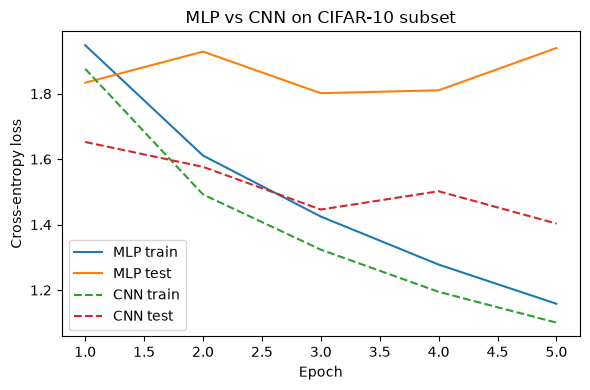

In [12]:
epochs = range(1, len(mlp_hist["train_loss"]) + 1)

plt.figure(figsize=(6, 4))
plt.plot(epochs, mlp_hist["train_loss"], label="MLP train")
plt.plot(epochs, mlp_hist["test_loss"], label="MLP test")
plt.plot(epochs, cnn_hist["train_loss"], label="CNN train", linestyle="--")
plt.plot(epochs, cnn_hist["test_loss"], label="CNN test", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MLP vs CNN on CIFAR-10 subset")
plt.legend()
plt.tight_layout()